In [1]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, confusion_matrix


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier


In [4]:

nltk.download('stopwords')


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ragha\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [5]:

fake = pd.read_csv(r"C:\Users\ragha\Downloads\archive (1)\Fake.csv")
true = pd.read_csv(r"C:\Users\ragha\Downloads\archive (1)\True.csv")


In [6]:
fake["label"] = "FAKE"
true["label"] = "REAL"

In [7]:
data = pd.concat([fake, true], ignore_index=True)

# Reduce dataset size for faster training
data = data.sample(n=5000, random_state=42)

print(data.head())
print("Dataset Shape:", data.shape)

                                                   title  \
22216  Ben Stein Calls Out 9th Circuit Court: Committ...   
27917  Trump drops Steve Bannon from National Securit...   
25007  Puerto Rico expects U.S. to lift Jones Act shi...   
1377    OOPS: Trump Just Accidentally Confirmed He Le...   
32476  Donald Trump heads for Scotland to reopen a go...   

                                                    text       subject  \
22216  21st Century Wire says Ben Stein, reputable pr...       US_News   
27917  WASHINGTON (Reuters) - U.S. President Donald T...  politicsNews   
25007  (Reuters) - Puerto Rico Governor Ricardo Rosse...  politicsNews   
1377   On Monday, Donald Trump once again embarrassed...          News   
32476  GLASGOW, Scotland (Reuters) - Most U.S. presid...  politicsNews   

                      date label  
22216    February 13, 2017  FAKE  
27917       April 5, 2017   REAL  
25007  September 27, 2017   REAL  
1377          May 22, 2017  FAKE  
32476       June 24

In [8]:
print("Dataset shape:", data.shape)
print(data.head())


Dataset shape: (5000, 5)
                                                   title  \
22216  Ben Stein Calls Out 9th Circuit Court: Committ...   
27917  Trump drops Steve Bannon from National Securit...   
25007  Puerto Rico expects U.S. to lift Jones Act shi...   
1377    OOPS: Trump Just Accidentally Confirmed He Le...   
32476  Donald Trump heads for Scotland to reopen a go...   

                                                    text       subject  \
22216  21st Century Wire says Ben Stein, reputable pr...       US_News   
27917  WASHINGTON (Reuters) - U.S. President Donald T...  politicsNews   
25007  (Reuters) - Puerto Rico Governor Ricardo Rosse...  politicsNews   
1377   On Monday, Donald Trump once again embarrassed...          News   
32476  GLASGOW, Scotland (Reuters) - Most U.S. presid...  politicsNews   

                      date label  
22216    February 13, 2017  FAKE  
27917       April 5, 2017   REAL  
25007  September 27, 2017   REAL  
1377          May 22, 2017  F

In [9]:

print("\nMissing values:")
print(data.isnull().sum())



Missing values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64


In [10]:
data["content"] = data["title"] + " " + data["text"]


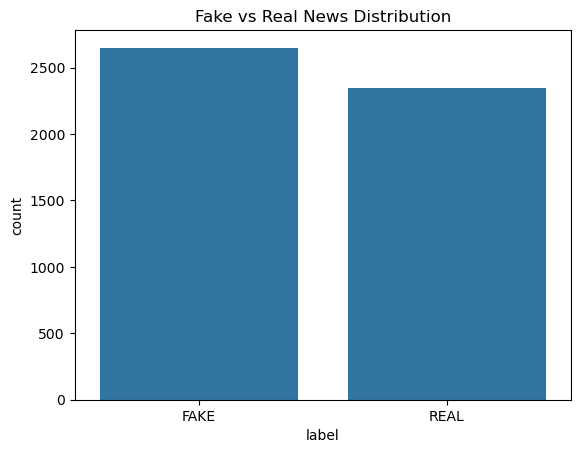

In [11]:
sns.countplot(x="label", data=data)
plt.title("Fake vs Real News Distribution")
plt.show()



In [12]:

data["text_length"] = data["content"].apply(len)

numeric_data = data[["text_length"]]


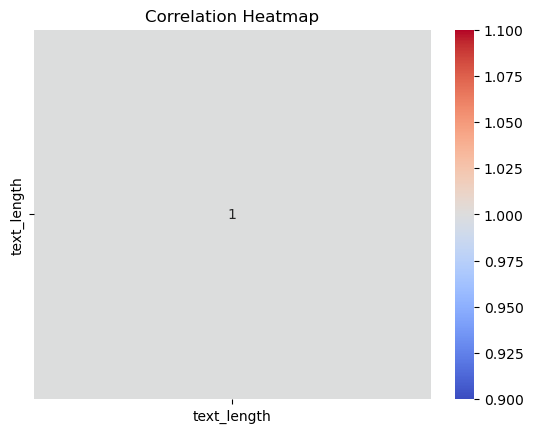

In [13]:
sns.heatmap(numeric_data.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


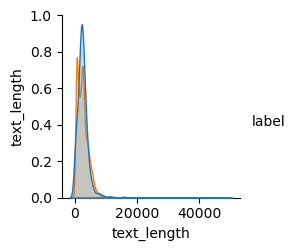

In [14]:

sns.pairplot(data[["text_length","label"]], hue="label")
plt.show()


In [15]:
stop_words = set(stopwords.words("english"))

def clean_text(text):

    text = re.sub("[^a-zA-Z]", " ", str(text))
    text = text.lower()

    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

data["content"] = data["content"].apply(clean_text)


In [16]:

tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(data["content"]).toarray()

y = data["label"]


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


In [28]:
models = {

"Logistic Regression": LogisticRegression(max_iter=1000),

"Naive Bayes": MultinomialNB(),

"SVM": LinearSVC(),

"Random Forest": RandomForestClassifier(),

"AdaBoost": AdaBoostClassifier(),

"Gradient Boosting": GradientBoostingClassifier(n_estimators=20, max_depth=3)

}

In [29]:
results = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results[name] = accuracy

    print(name, "Accuracy:", accuracy)


Training: Logistic Regression
Logistic Regression Accuracy: 0.977

Training: Naive Bayes
Naive Bayes Accuracy: 0.937

Training: SVM
SVM Accuracy: 0.986

Training: Random Forest
Random Forest Accuracy: 0.993

Training: AdaBoost
AdaBoost Accuracy: 0.994

Training: Gradient Boosting
Gradient Boosting Accuracy: 0.993


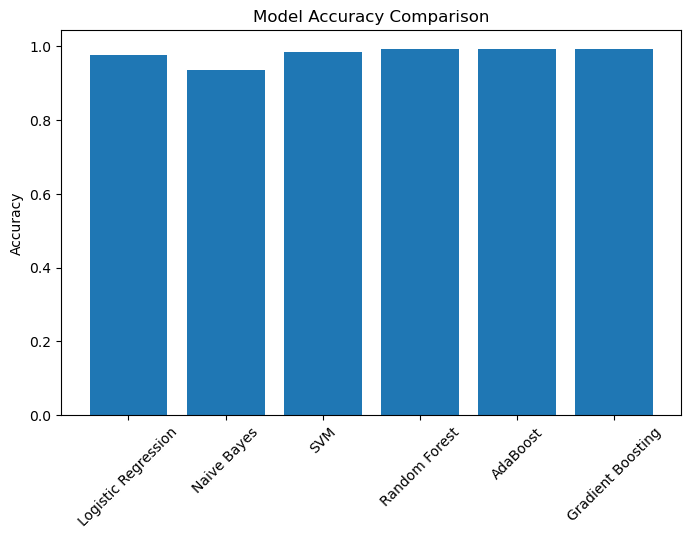

In [20]:

plt.figure(figsize=(8,5))
plt.bar(results.keys(), results.values())
plt.xticks(rotation=45)
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")
plt.show()


In [21]:

best_model_name = max(results, key=results.get)

print("\nBest Model:", best_model_name)

best_model = models[best_model_name]



Best Model: Random Forest


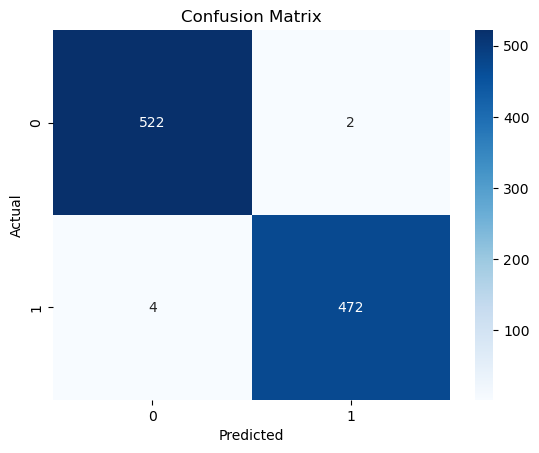

In [22]:

pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [23]:

def predict_news(news):

    cleaned = clean_text(news)

    vector = tfidf.transform([cleaned]).toarray()

    prediction = best_model.predict(vector)

    print("\nNews:", news)

    print("Prediction:", prediction[0])


In [24]:
predict_news("Government launches new education policy")

predict_news("Aliens landed in India yesterday night")


News: Government launches new education policy
Prediction: FAKE

News: Aliens landed in India yesterday night
Prediction: FAKE


In [32]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score


In [33]:
param_grid = {
    'n_estimators': [50,100,150],
    'max_depth': [None,10,20],
    'min_samples_split': [2,5],
    'min_samples_leaf': [1,2]
}


In [36]:
rf = RandomForestClassifier()

In [37]:
grid_search = GridSearchCV(
    rf,
    param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)



In [38]:
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)

best_rf = grid_search.best_estimator_

pred = best_rf.predict(X_test)

print("Accuracy after tuning:", accuracy_score(y_test, pred))

Best Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}
Accuracy after tuning: 0.993


In [ ]:
-